In [12]:
import wfdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW = "../data/raw/training/"
LABELS = {"N": "Normal", "A": "AF", "O": "Other rhythm", "~": "Noisy"}

ref = pd.read_csv(RAW + "REFERENCE-v3.csv", header=None, names=["record", "label"])

# each record is in a subfolder named after its first 3 characters: A00001 -> A00/A00001
ref["record"] = ref["record"].str.split("/").str[-1]
ref["path"] = RAW + ref["record"].str[:3] + "/" + ref["record"]

print(len(ref), "recordings")
print(ref["label"].map(LABELS).value_counts())

8528 recordings
label
Normal          5076
Other rhythm    2415
AF               758
Noisy            279
Name: count, dtype: int64


In [13]:
v0 = pd.read_csv(RAW + "REFERENCE-v0.csv", header=None, names=["record", "label_v0"])
v0["record"] = v0["record"].str.split("/").str[-1]

print(ref.head(3))
print(v0.head(3))

both = ref.merge(v0, on="record")
print("matched records:", len(both))
print("changed labels:", (both["label"] != both["label_v0"]).sum())

   record label                             path
0  A00001     N  ../data/raw/training/A00/A00001
1  A00002     N  ../data/raw/training/A00/A00002
2  A00003     N  ../data/raw/training/A00/A00003
   record label_v0
0  A00001        N
1  A00002        N
2  A00003        N
matched records: 8528
changed labels: 412


In [15]:
v0 = pd.read_csv(RAW + "REFERENCE-v0.csv", header=None, names=["record", "label_v0"])
v0["record"] = v0["record"].str.split("/").str[-1]      # same name format as ref

both = ref.merge(v0, on="record")
changed = both[both["label"] != both["label_v0"]]

print(f"{len(changed)} of {len(both)} labels changed between v0 and v3")
print(pd.crosstab(changed["label_v0"].map(LABELS), changed["label"].map(LABELS)))

412 of 8528 labels changed between v0 and v3
label         AF  Noisy  Normal  Other rhythm
label_v0                                     
AF             0     32      19            36
Normal         9    114       0            12
Other rhythm  65     87      38             0


In [16]:
ref["seconds"] = [wfdb.rdheader(p).sig_len / 300 for p in ref["path"]]
print(ref["seconds"].describe())
ref.groupby(ref["label"].map(LABELS))["seconds"].describe()

count    8528.000000
mean       32.497468
std        10.889442
min         9.046667
25%        30.000000
50%        30.000000
75%        30.000000
max        60.953333
Name: seconds, dtype: float64


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
AF,758.0,32.344692,12.323600,9.986667,30.00,30.0,30.0,60.206667
Noisy,279.0,24.378769,10.426761,9.360000,14.81,30.0,30.0,60.000000
Normal,5076.0,32.111275,9.973795,9.046667,30.00,30.0,30.0,60.953333
Other rhythm,2415.0,34.295081,11.764910,9.126667,30.00,30.0,30.0,60.860000


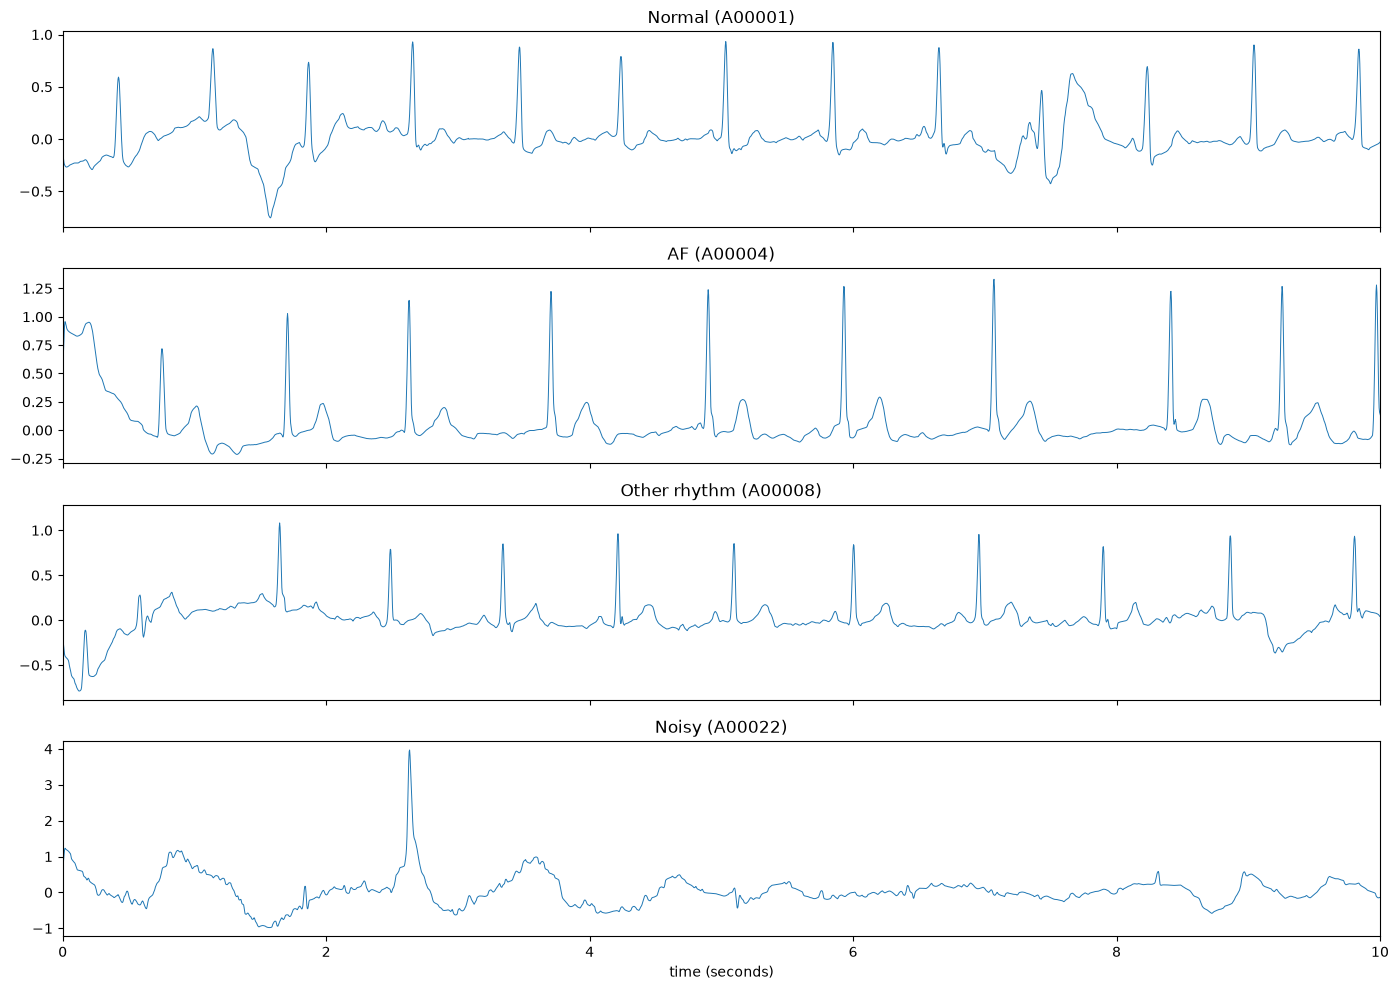

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
for ax, (code, name) in zip(axes, LABELS.items()):
    row = ref[ref["label"] == code].iloc[0]
    sig = wfdb.rdrecord(row["path"]).p_signal[:, 0]
    t = np.arange(len(sig)) / 300
    ax.plot(t, sig, lw=0.7)
    ax.set_title(f"{name} ({row['record']})")
    ax.set_xlim(0, 10)          
axes[-1].set_xlabel("time (seconds)")
fig.tight_layout()
plt.show()

In [2]:
import pandas as pd
f = pd.read_csv("../data/processed/hrv_features.csv")
print(f.groupby("class_name")["frac_implausible_rr"].apply(lambda x: (x > 0).mean()).round(3))

class_name
AF              0.040
Noisy           0.308
Normal          0.038
Other rhythm    0.054
Name: frac_implausible_rr, dtype: float64


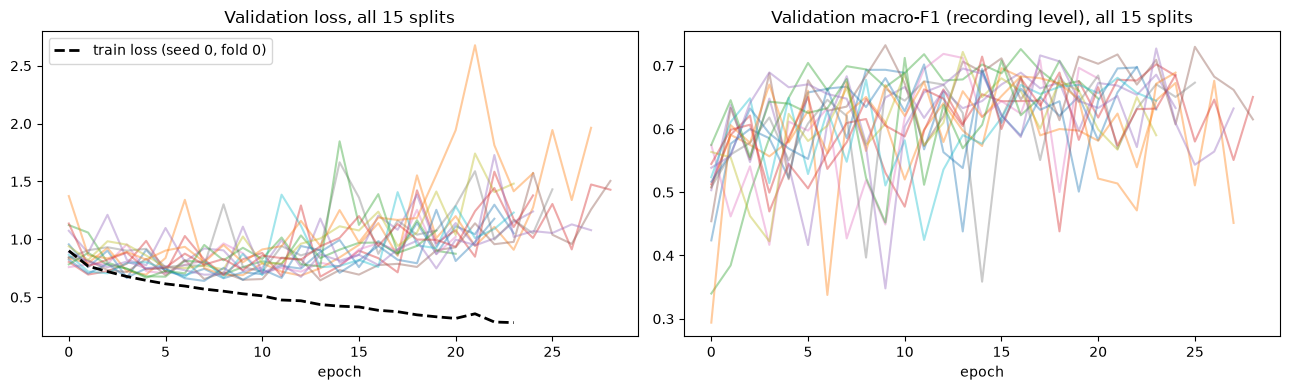

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

h = pd.read_csv("../results/cnn_history.csv")
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
for (s, f), g in h.groupby(["seed", "fold"]):
    a.plot(g["epoch"], g["val_loss"], alpha=0.4)
    b.plot(g["epoch"], g["val_macro_f1"], alpha=0.4)
rep = h[(h.seed == 0) & (h.fold == 0)]
a.plot(rep["epoch"], rep["train_loss"], "k--", lw=2, label="train loss (seed 0, fold 0)")
a.set_title("Validation loss, all 15 splits"); a.set_xlabel("epoch"); a.legend()
b.set_title("Validation macro-F1 (recording level), all 15 splits"); b.set_xlabel("epoch")
plt.tight_layout(); plt.show()


In [2]:
import sys; sys.path.append("../scripts")
import numpy as np, pandas as pd
from importlib import import_module
cnn = import_module("05_cnn_v3")

signals = pd.read_pickle("../data/processed/signals.pkl")
meta = pd.read_csv("../data/processed/meta.csv")
splits = pd.read_csv("../results/splits.csv")

train_rec = np.where(splits["fold_seed0"] != 0)[0]
X, owner = cnn.make_windows(signals, train_rec)
y = meta["label"].values[owner]

print("shape:", X.shape)                       # (number of windows, 1, 2100)
print("mean, std of one window:", X[0].mean().round(3), X[0].std().round(3))
print(pd.Series(y).map({"N": "Normal", "A": "AF", "O": "Other", "~": "Noisy"}).value_counts())

shape: (28875, 1, 2100)
mean, std of one window: 0.0 1.0
Normal    17056
Other      8642
AF         2533
Noisy       644
Name: count, dtype: int64
